# Distribución de confianza de SANv2 en CROHME 2014

Este notebook ejecuta **SANv2** sobre las 986 imágenes del split CROHME 2014, utilizado como conjunto de experimentación, y estudia tres puntuaciones globales de confianza construidas con la probabilidad asignada a cada token elegido durante la decodificación:

$$s_{\mathrm{sum}}(x)=\sum_{i=1}^{n}\log p_i,$$

$$s_{\mathrm{avg}}(x)=\frac{1}{n}\sum_{i=1}^{n}\log p_i,$$

$$s_{\mathrm{min}}(x)=\min_{1\le i\le n}\log p_i.$$

En las tres medidas, un valor más cercano a cero indica mayor confianza. Chow-Sum acumula evidencia y depende de la longitud; Chow-Average corrige esa dependencia; Chow-Quantile-0 representa la decisión de menor confianza de la secuencia.

La evaluación de exactitud sigue el protocolo común documentado en `01_seleccion/resumen_comparacion_san_posformer_crohme_2014.md`: se adopta la anotación de Modelo2 como referencia, se normalizan espacios y se elimina únicamente el token `\limits`.

## Política para las probabilidades

- Se usa `selected_probability`, obtenida mediante `softmax` sobre los logits del vocabulario de SANv2.
- Se excluye `<eos>` porque no forma parte de la expresión predicha $\hat{y}$.
- Se conserva `struct`, pues es una decisión del decodificador que determina la construcción del árbol.
- Las relaciones estructurales usan probabilidades sigmoid independientes. Se resumen y exportan por separado, pero no se mezclan con las tres puntuaciones basadas en tokens para evitar combinar distribuciones con semánticas diferentes.
- Las probabilidades se recortan numéricamente a $[10^{-12},1]$ antes de aplicar el logaritmo.

In [12]:
from pathlib import Path
import gc
import json
import platform
import sys
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

def find_project_root():
    candidates = [Path.cwd(), *Path.cwd().parents, Path.cwd() / '..', Path.cwd() / '../..']
    for candidate in candidates:
        candidate = candidate.resolve()
        if all((candidate / name).is_dir() for name in ('SANv2', 'Cascada', 'data')):
            return candidate
    raise FileNotFoundError('No se encontró la raíz con SANv2/, Cascada/ y data/.')

ROOT = find_project_root()
SANV2_ROOT = ROOT / 'SANv2'
RESULTS_DIR = ROOT / 'Cascada' / '03_analisis' / 'resultados'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('Raíz     :', ROOT)
print('Dispositivo:', DEVICE)
print('Python   :', platform.python_version())
print('PyTorch  :', torch.__version__)

Raíz     : C:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas
Dispositivo: cuda:0
Python   : 3.8.10
PyTorch  : 2.0.1+cu118


## Configuración e inventario del conjunto de experimentación

Las imágenes y la referencia canónica proceden de Modelo2, igual que en la evaluación común normalizada. Los identificadores se alinean por nombre, nunca por posición.

In [13]:
YEAR = '2014'
MAX_SAMPLES = None       # Use un entero para una prueba corta.
PROGRESS_EVERY = 25
EPSILON = 1e-12
INCLUDE_EOS = False
INCLUDE_STRUCT = True

M2_DIR = ROOT / 'data' / 'Modelo2' / YEAR
IMAGE_DIR = M2_DIR / 'img'
CAPTION_PATH = M2_DIR / 'caption.txt'
PRIOR_COMPARISON_PATH = (
    ROOT / 'Cascada' / '01_seleccion' / 'resultados' /
    'comparacion_san_posformer_crohme_2014.csv'
)

def read_captions(path):
    captions = {}
    order = []
    for line_number, line in enumerate(path.read_text(encoding='utf-8').splitlines(), start=1):
        parts = line.strip().split()
        if not parts:
            continue
        sample_id = parts[0][:-4] if parts[0].endswith('.jpg') else parts[0]
        if sample_id in captions:
            raise ValueError(f'ID duplicado en la línea {line_number}: {sample_id}')
        captions[sample_id] = ' '.join(parts[1:])
        order.append(sample_id)
    return captions, order

captions, sample_order = read_captions(CAPTION_PATH)
sample_ids = sample_order[:MAX_SAMPLES] if MAX_SAMPLES is not None else sample_order
missing_images = [sid for sid in sample_ids if not (IMAGE_DIR / f'{sid}.bmp').is_file()]
if missing_images:
    raise FileNotFoundError(f'Faltan {len(missing_images)} imágenes; primera: {missing_images[0]}')
if MAX_SAMPLES is None and len(sample_ids) != 986:
    raise ValueError(f'Se esperaban 986 muestras y se encontraron {len(sample_ids)}.')

display(pd.DataFrame({
    'indicador': ['Expresiones', 'Imágenes faltantes', 'Referencia canónica'],
    'valor': [len(sample_ids), len(missing_images), 'Modelo2'],
}))

,indicador,valor
0,Expresiones,986
1,Imágenes faltantes,0
2,Referencia canónica,Modelo2


## Carga de SANv2

Se carga el checkpoint copiado en `SANv2`. El modelo queda en modo evaluación, sin gradientes. La extracción de probabilidades no añade parámetros entrenables.

In [14]:
sys.path.insert(0, str(SANV2_ROOT))
from utils import load_config
from infer.Backbone import Backbone
from dataset import Words

san_params = load_config(SANV2_ROOT / '14.yaml')
san_params['device'] = DEVICE
san_params['word_path'] = str(SANV2_ROOT / 'data' / 'word.txt')
san_params['checkpoint'] = str(SANV2_ROOT / 'checkpoints' / 'SAN_decoder' / 'best.pth')
san_words = Words(san_params['word_path'])
san_params['word_num'] = len(san_words)
san_params['struct_num'] = 7
san_params['words'] = san_words

san_model = Backbone(san_params)
san_state = torch.load(san_params['checkpoint'], map_location='cpu')
san_model.load_state_dict(san_state['model'])
san_model = san_model.to(DEVICE).eval().requires_grad_(False)

print('Checkpoint:', san_params['checkpoint'])
print(f'Parámetros: {sum(parameter.numel() for parameter in san_model.parameters()):,}')

try UTF-8 encoding
115 symbols in total
Checkpoint: C:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas\SANv2\checkpoints\SAN_decoder\best.pth
Parámetros: 7,996,103


## Funciones de decodificación, normalización y confianza

In [15]:
def load_grayscale(path):
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise FileNotFoundError(path)
    return image

def prepare_san(image):
    tensor = torch.from_numpy(image.copy()).float().div_(255).unsqueeze(0).unsqueeze(0)
    mask = torch.ones_like(tensor)
    return tensor.to(DEVICE), mask.to(DEVICE)

def san_prediction_to_latex(prediction):
    if prediction is None or len(prediction) <= 1:
        return '<sin predicción>'
    children = {}
    for item in prediction:
        if len(item) < 4:
            continue
        node_id, parent_id = int(item[1]), int(item[2])
        children.setdefault(parent_id, []).append((node_id, str(item[3])))

    def walk(node_id):
        if node_id < 0 or node_id >= len(prediction):
            return ['<invalid>']
        symbol = str(prediction[node_id][0])
        kids = children.get(node_id, [])
        if not kids:
            return [symbol]
        result = [symbol]
        if symbol == r'\frac':
            for relation_name in ('Above', 'Below'):
                for child_id, relation in kids:
                    if relation == relation_name:
                        result += ['{'] + walk(child_id) + ['}']
            for child_id, relation in kids:
                if relation == 'Right':
                    result += walk(child_id)
            return result
        for child_id, relation in kids:
            if relation == 'l_sup':
                result += ['['] + walk(child_id) + [']']
        for child_id, relation in kids:
            if relation == 'Inside':
                result += ['{'] + walk(child_id) + ['}']
        for child_id, relation in kids:
            if relation in ('Sub', 'Below'):
                result += ['_', '{'] + walk(child_id) + ['}']
        for child_id, relation in kids:
            if relation in ('Sup', 'Above'):
                result += ['^', '{'] + walk(child_id) + ['}']
        for child_id, relation in kids:
            if relation == 'Right':
                result += walk(child_id)
        return result

    return ' '.join(walk(1))

def normalize_spaces(text):
    return ' '.join(str(text).split())

def normalize_common(text):
    return ' '.join(token for token in str(text).split() if token != r'\limits')

def selected_token_probabilities(trace, include_eos=False, include_struct=True):
    selected_tokens = []
    selected_probabilities = []
    for step in trace:
        token = step['selected_token']
        if not include_eos and token == '<eos>':
            continue
        if not include_struct and token == 'struct':
            continue
        selected_tokens.append(token)
        selected_probabilities.append(float(step['selected_probability']))
    if not selected_probabilities:
        raise ValueError('La traza no contiene tokens válidos para calcular confianza.')
    return selected_tokens, np.asarray(selected_probabilities, dtype=np.float64)

def confidence_scores(probabilities, epsilon=EPSILON):
    probabilities = np.clip(np.asarray(probabilities, dtype=np.float64), epsilon, 1.0)
    log_probabilities = np.log(probabilities)
    return {
        'chow_sum': float(log_probabilities.sum()),
        'chow_average': float(log_probabilities.mean()),
        'chow_quantile_0': float(log_probabilities.min()),
        'token_count_confidence': int(probabilities.size),
        'selected_probability_mean': float(probabilities.mean()),
        'selected_probability_min': float(probabilities.min()),
    }

def relation_summary(trace):
    values = [
        float(probability)
        for step in trace
        for probability in step.get('relation_probabilities', {}).values()
    ]
    if not values:
        return {'relation_probability_count': 0, 'relation_probability_mean': np.nan, 'relation_probability_min': np.nan}
    values = np.asarray(values, dtype=np.float64)
    return {
        'relation_probability_count': int(values.size),
        'relation_probability_mean': float(values.mean()),
        'relation_probability_min': float(values.min()),
    }

## Inferencia sobre CROHME 2014

Además de las tres puntuaciones, se conservan la predicción, la referencia normalizada, el número de decisiones y resúmenes auxiliares. La distribución completa por token permanece disponible en la traza durante la inferencia, pero no se replica dentro del CSV para evitar un archivo excesivamente ancho.

In [16]:
rows = []
for index, sample_id in enumerate(sample_ids, start=1):
    image_path = IMAGE_DIR / f'{sample_id}.bmp'
    row = {
        'index': index,
        'sample_id': sample_id,
        'image_file': image_path.name,
        'status': 'ok',
        'error': '',
    }
    try:
        image = load_grayscale(image_path)
        row['height'], row['width'] = image.shape
        image_tensor, image_mask = prepare_san(image)

        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
        start = time.perf_counter()
        with torch.inference_mode():
            prediction_tree, probability_trace = san_model(
                image_tensor, image_mask, return_probabilities=True
            )
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
        inference_time_ms = (time.perf_counter() - start) * 1000

        prediction = san_prediction_to_latex(prediction_tree)
        normalized_prediction = normalize_common(prediction)
        normalized_ground_truth = normalize_common(captions[sample_id])
        selected_tokens, probabilities = selected_token_probabilities(
            probability_trace,
            include_eos=INCLUDE_EOS,
            include_struct=INCLUDE_STRUCT,
        )

        row.update({
            'ground_truth_raw': captions[sample_id],
            'ground_truth_normalized': normalized_ground_truth,
            'san_prediction_raw': prediction,
            'san_prediction_normalized': normalized_prediction,
            'correct_common_normalized': int(normalized_prediction == normalized_ground_truth),
            'inference_time_ms': inference_time_ms,
            'decoder_steps_total': len(probability_trace),
            'struct_steps': sum(step['selected_token'] == 'struct' for step in probability_trace),
            'selected_tokens_json': json.dumps(selected_tokens, ensure_ascii=False),
            'selected_probabilities_json': json.dumps(probabilities.tolist()),
            **confidence_scores(probabilities),
            **relation_summary(probability_trace),
        })
        del image, image_tensor, image_mask, prediction_tree, probability_trace
    except Exception as exc:
        row.update({'status': 'error', 'error': f'{type(exc).__name__}: {exc}'})
        if 'out of memory' in str(exc).lower():
            rows.append(row)
            raise
    rows.append(row)
    gc.collect()
    if index == 1 or index % PROGRESS_EVERY == 0 or index == len(sample_ids):
        valid_so_far = sum(item['status'] == 'ok' for item in rows)
        print(f'{index:4d}/{len(sample_ids)} | válidas={valid_so_far:4d}')

   1/986 | válidas=   1
  25/986 | válidas=  25
  50/986 | válidas=  50
  75/986 | válidas=  75
 100/986 | válidas= 100
 125/986 | válidas= 125
 150/986 | válidas= 150
 175/986 | válidas= 175
 200/986 | válidas= 200
 225/986 | válidas= 225
 250/986 | válidas= 250
 275/986 | válidas= 275
 300/986 | válidas= 300
 325/986 | válidas= 325
 350/986 | válidas= 350
 375/986 | válidas= 375
 400/986 | válidas= 400
 425/986 | válidas= 425
 450/986 | válidas= 450
 475/986 | válidas= 475
 500/986 | válidas= 500
 525/986 | válidas= 525
 550/986 | válidas= 550
 575/986 | válidas= 575
 600/986 | válidas= 600
 625/986 | válidas= 625
 650/986 | válidas= 650
 675/986 | válidas= 675
 700/986 | válidas= 700
 725/986 | válidas= 725
 750/986 | válidas= 750
 775/986 | válidas= 775
 800/986 | válidas= 800
 825/986 | válidas= 825
 850/986 | válidas= 850
 875/986 | válidas= 875
 900/986 | válidas= 900
 925/986 | válidas= 925
 950/986 | válidas= 950
 975/986 | válidas= 975
 986/986 | válidas= 986


## Validaciones

Se comprueba que las métricas sean finitas y coherentes. Si está disponible el CSV de la comparación anterior, también se verifica que SANv2 conserve exactamente las predicciones normalizadas de SAN; esta prueba detecta cambios accidentales causados por la instrumentación de probabilidades.

In [17]:
results = pd.DataFrame(rows)
valid = results.loc[results['status'] == 'ok'].copy()
errors = results.loc[results['status'] != 'ok'].copy()
if valid.empty:
    raise RuntimeError('No hubo resultados válidos.')

score_columns = ['chow_sum', 'chow_average', 'chow_quantile_0']
if not np.isfinite(valid[score_columns].to_numpy()).all():
    raise ValueError('Se detectaron puntuaciones no finitas.')
if not (valid['chow_sum'] <= valid['chow_average'] + 1e-12).all():
    raise ValueError('Chow-Sum debe ser menor o igual que Chow-Average.')
if not (valid['chow_quantile_0'] <= valid['chow_average'] + 1e-12).all():
    raise ValueError('Chow-Quantile-0 debe ser menor o igual que Chow-Average.')

if MAX_SAMPLES is None and PRIOR_COMPARISON_PATH.is_file():
    prior = pd.read_csv(PRIOR_COMPARISON_PATH, usecols=['sample_id', 'san_common_prediction'])
    check = valid.merge(prior, on='sample_id', how='left', validate='one_to_one')
    check['same_prediction'] = (
        check['san_prediction_normalized'].map(normalize_common)
        == check['san_common_prediction'].map(normalize_common)
    )
    if not check['same_prediction'].all():
        mismatches = check.loc[~check['same_prediction'], [
            'sample_id', 'san_prediction_normalized', 'san_common_prediction'
        ]]
        raise AssertionError(f'SANv2 difiere de SAN en {len(mismatches)} predicciones.')
    print('Predicciones SANv2 idénticas a la comparación previa:', len(check))

print(f'Válidas: {len(valid)} | Errores: {len(errors)}')
print(f'Exact match normalizado: {int(valid["correct_common_normalized"].sum())}/{len(valid)} '
      f'({100 * valid["correct_common_normalized"].mean():.2f}%)')
if not errors.empty:
    display(errors[['sample_id', 'error']])

Predicciones SANv2 idénticas a la comparación previa: 986
Válidas: 986 | Errores: 0
Exact match normalizado: 560/986 (56.80%)


## Resumen numérico de las distribuciones

Las distribuciones se presentan globalmente y separadas según el exact match común normalizado. Esta separación permite comprobar si los errores tienden a recibir menor confianza.

In [18]:
metric_labels = {
    'chow_sum': 'Chow-Sum',
    'chow_average': 'Chow-Average',
    'chow_quantile_0': 'Chow-Quantile-0',
}
quantiles = [0.00, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 1.00]
distribution_rows = []
for metric in score_columns:
    for correctness, subset in [('Todas', valid), ('Correctas', valid[valid['correct_common_normalized'] == 1]), ('Incorrectas', valid[valid['correct_common_normalized'] == 0])]:
        values = subset[metric]
        row = {
            'métrica': metric_labels[metric],
            'grupo': correctness,
            'n': len(values),
            'media': values.mean(),
            'desviación': values.std(ddof=1),
        }
        row.update({f'q{int(q * 100):02d}': values.quantile(q) for q in quantiles})
        distribution_rows.append(row)
distribution_summary = pd.DataFrame(distribution_rows)
display(distribution_summary.style.format(precision=6))

,métrica,grupo,n,media,desviación,q00,q01,q05,q25,q50,q75,q95,q99,q100
0,Chow-Sum,Todas,986,-0.491798,1.200084,-16.423439,-5.507477,-2.115442,-0.533985,-0.076933,-0.003881,-0.000183,-0.000022,-0.000001
1,Chow-Sum,Correctas,560,-0.117247,0.262460,-2.484591,-1.086617,-0.645824,-0.083630,-0.008765,-0.001000,-0.000126,-0.000015,-0.000001
2,Chow-Sum,Incorrectas,426,-0.984166,1.679115,-16.423439,-8.083345,-3.594364,-1.050881,-0.503343,-0.150957,-0.002843,-0.000121,-0.000008
3,Chow-Average,Todas,986,-0.041204,0.082179,-1.064196,-0.333123,-0.178179,-0.046423,-0.007844,-0.000539,-0.000024,-0.000005,-0.000001
4,Chow-Average,Correctas,560,-0.016660,0.045973,-0.621148,-0.200569,-0.098544,-0.009076,-0.001081,-0.000145,-0.000018,-0.000004,-0.000001
5,Chow-Average,Incorrectas,426,-0.073468,0.105047,-1.064196,-0.434662,-0.252836,-0.093085,-0.039875,-0.015944,-0.000496,-0.000031,-0.000003
6,Chow-Quantile-0,Todas,986,-0.262719,0.398742,-2.655794,-1.874958,-1.076371,-0.418105,-0.056980,-0.002941,-0.000091,-0.000012,-0.000001
7,Chow-Quantile-0,Correctas,560,-0.099476,0.222915,-2.458077,-0.888434,-0.594145,-0.072217,-0.007050,-0.000609,-0.000063,-0.000009,-0.000001
8,Chow-Quantile-0,Incorrectas,426,-0.477312,0.471025,-2.655794,-2.083080,-1.440165,-0.664747,-0.381970,-0.112567,-0.002227,-0.000075,-0.000004


## Histogramas de confianza

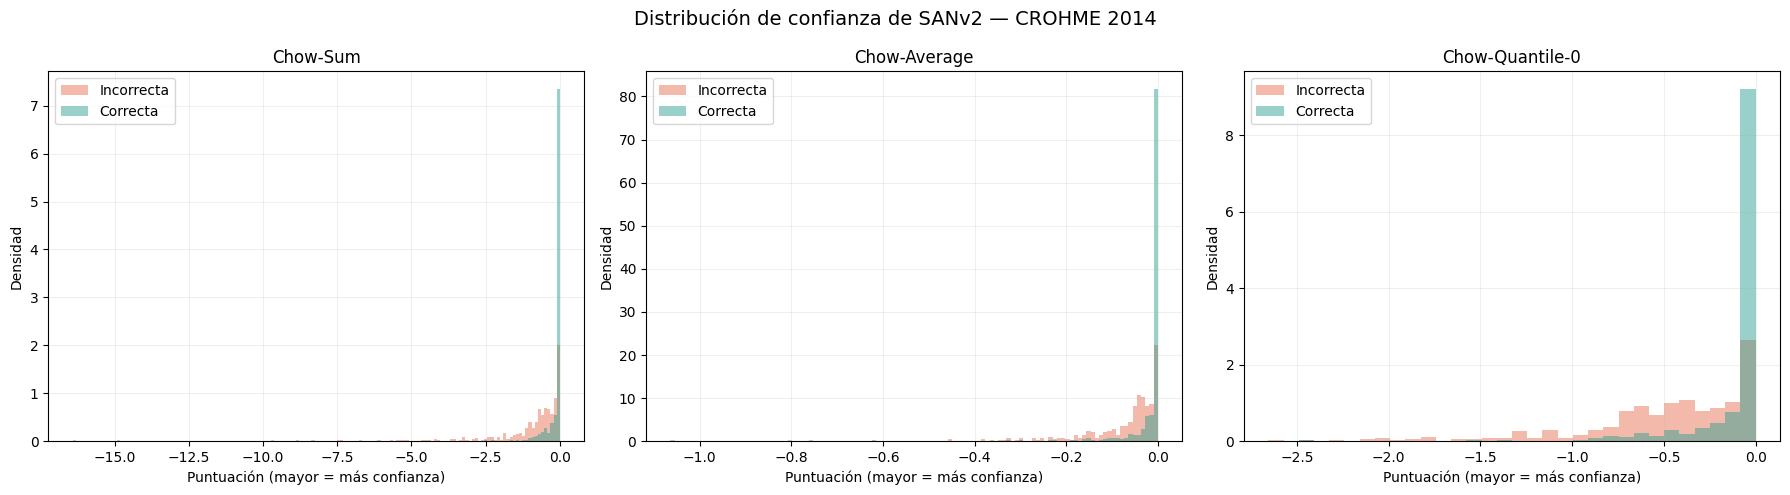

Gráfica: C:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas\Cascada\03_analisis\resultados\distribuciones_confianza_sanv2_crohme_2014.png


In [19]:
colors = {0: '#e76f51', 1: '#2a9d8f'}
labels = {0: 'Incorrecta', 1: 'Correcta'}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for axis, metric in zip(axes, score_columns):
    combined = valid[metric].to_numpy()
    bins = np.histogram_bin_edges(combined, bins='fd')
    if len(bins) < 2:
        bins = 20
    for correctness in (0, 1):
        values = valid.loc[valid['correct_common_normalized'] == correctness, metric]
        axis.hist(values, bins=bins, density=True, alpha=0.48, color=colors[correctness], label=labels[correctness])
    axis.set_title(metric_labels[metric])
    axis.set_xlabel('Puntuación (mayor = más confianza)')
    axis.set_ylabel('Densidad')
    axis.grid(alpha=0.2)
    axis.legend()
fig.suptitle('Distribución de confianza de SANv2 — CROHME 2014', fontsize=14)
fig.tight_layout()
histogram_path = RESULTS_DIR / 'distribuciones_confianza_sanv2_crohme_2014.png'
fig.savefig(histogram_path, dpi=180, bbox_inches='tight')
plt.show()
print('Gráfica:', histogram_path)

## Funciones de distribución acumulada empírica

Las curvas ECDF facilitan comparar toda la distribución sin depender de la elección de intervalos del histograma.

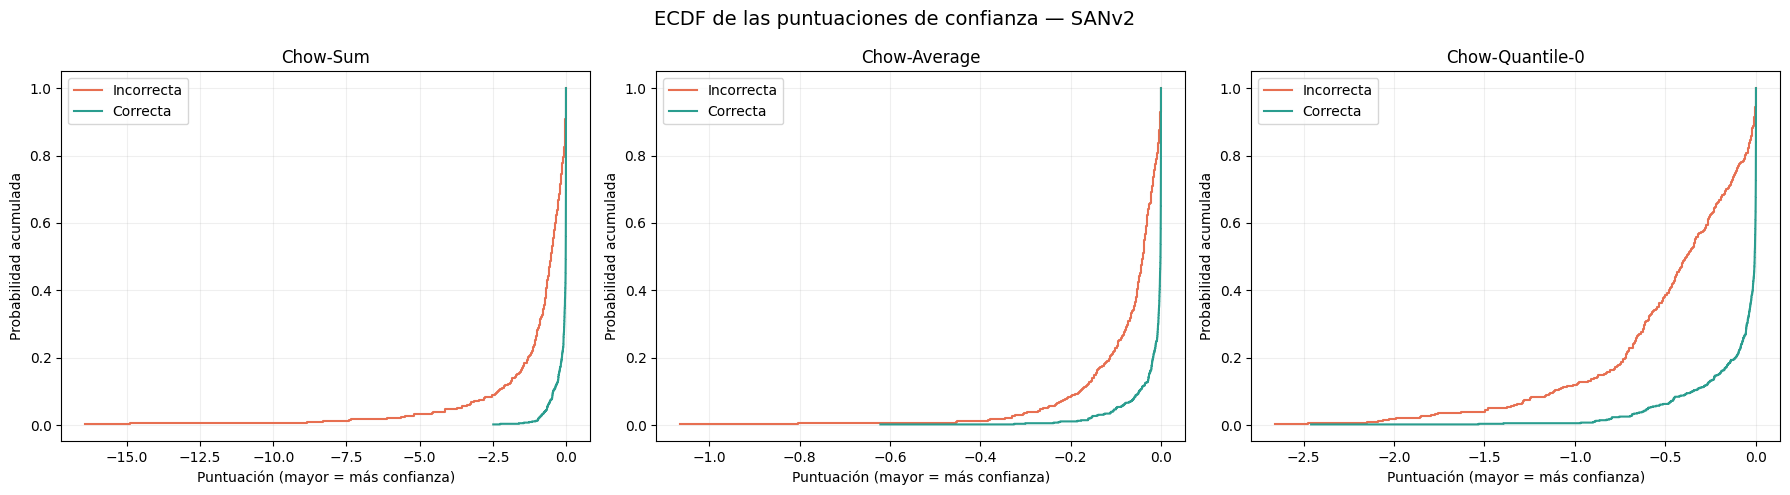

Gráfica: C:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas\Cascada\03_analisis\resultados\ecdf_confianza_sanv2_crohme_2014.png


In [20]:
def ecdf(values):
    x = np.sort(np.asarray(values, dtype=np.float64))
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for axis, metric in zip(axes, score_columns):
    for correctness in (0, 1):
        subset = valid.loc[valid['correct_common_normalized'] == correctness, metric]
        x, y = ecdf(subset)
        axis.step(x, y, where='post', color=colors[correctness], label=labels[correctness])
    axis.set_title(metric_labels[metric])
    axis.set_xlabel('Puntuación (mayor = más confianza)')
    axis.set_ylabel('Probabilidad acumulada')
    axis.grid(alpha=0.2)
    axis.legend()
fig.suptitle('ECDF de las puntuaciones de confianza — SANv2', fontsize=14)
fig.tight_layout()
ecdf_path = RESULTS_DIR / 'ecdf_confianza_sanv2_crohme_2014.png'
fig.savefig(ecdf_path, dpi=180, bbox_inches='tight')
plt.show()
print('Gráfica:', ecdf_path)

## Dependencia con la longitud

Este diagnóstico muestra por qué conviene comparar las tres medidas: Chow-Sum suele disminuir conforme aumenta el número de tokens, mientras que Chow-Average y Chow-Quantile-0 reducen o caracterizan de otra forma ese efecto.

,correlación Spearman con longitud
chow_sum,-0.3900
chow_average,-0.1266
chow_quantile_0,-0.3489


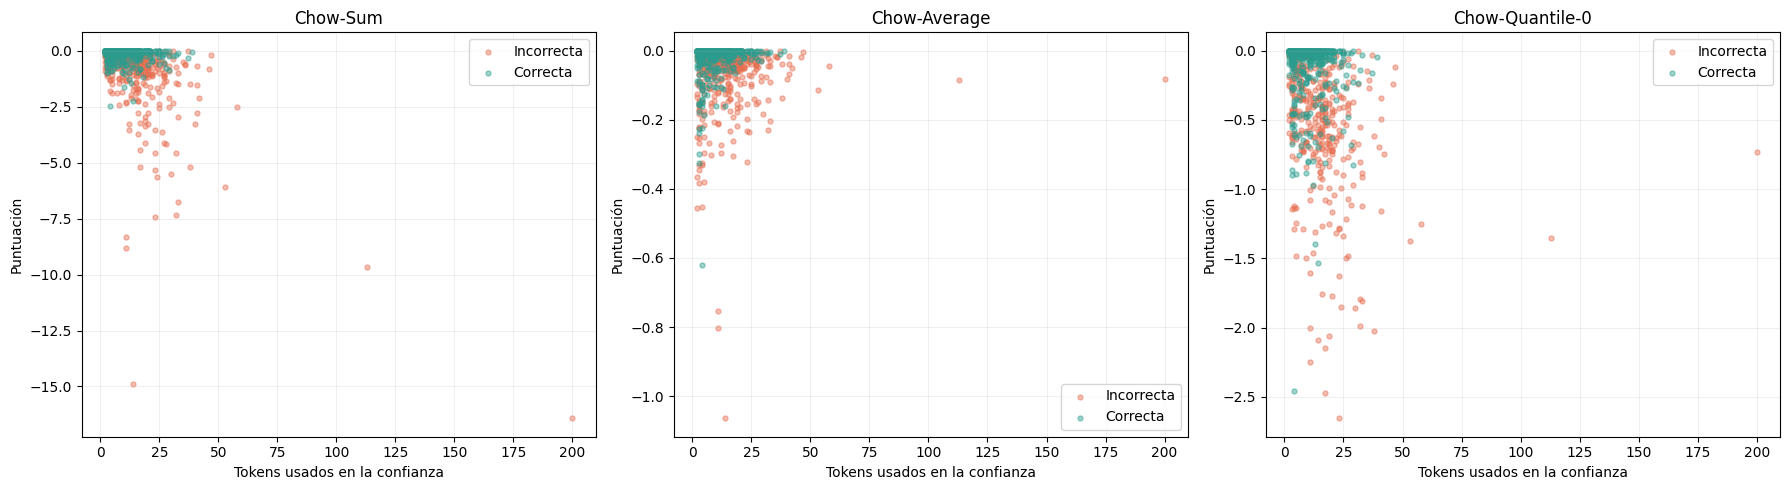

Gráfica: C:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas\Cascada\03_analisis\resultados\confianza_vs_longitud_sanv2_crohme_2014.png


In [21]:
length_correlations = valid[['token_count_confidence', *score_columns]].corr(method='spearman').loc[
    'token_count_confidence', score_columns
].rename('correlación Spearman con longitud').to_frame()
display(length_correlations.style.format('{:.4f}'))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for axis, metric in zip(axes, score_columns):
    for correctness in (0, 1):
        subset = valid[valid['correct_common_normalized'] == correctness]
        axis.scatter(
            subset['token_count_confidence'], subset[metric],
            s=13, alpha=0.45, color=colors[correctness], label=labels[correctness]
        )
    axis.set_title(metric_labels[metric])
    axis.set_xlabel('Tokens usados en la confianza')
    axis.set_ylabel('Puntuación')
    axis.grid(alpha=0.2)
    axis.legend()
fig.tight_layout()
length_path = RESULTS_DIR / 'confianza_vs_longitud_sanv2_crohme_2014.png'
fig.savefig(length_path, dpi=180, bbox_inches='tight')
plt.show()
print('Gráfica:', length_path)

## Capacidad discriminativa: AUROC descriptiva

Para cuantificar la separación observada en los histogramas y las ECDF se calcula una AUROC empírica. Aquí una predicción correcta es la clase positiva y una puntuación mayor representa más confianza. La implementación compara todos los pares correcta–incorrecta, por lo que no requiere dependencias adicionales.

La AUROC se calcula sobre CROHME 2014 como parte de la experimentación y puede utilizarse para comparar los medidores y seleccionar el criterio del *gate*. El medidor y los umbrales definidos con 2014 deberán mantenerse fijos al realizar las pruebas posteriores sobre CROHME 2016 y 2019.

In [22]:
def empirical_auc(scores, targets):
    scores = np.asarray(scores, dtype=np.float64)
    targets = np.asarray(targets, dtype=np.int8)
    positive = scores[targets == 1]
    negative = scores[targets == 0]
    if positive.size == 0 or negative.size == 0:
        raise ValueError('AUROC requiere ejemplos de ambas clases.')
    differences = positive[:, None] - negative[None, :]
    wins = np.count_nonzero(differences > 0)
    ties = np.count_nonzero(differences == 0)
    return (wins + 0.5 * ties) / differences.size

auroc_table = pd.DataFrame([
    {
        'métrica': metric_labels[metric],
        'columna': metric,
        'auroc_descriptiva': empirical_auc(
            valid[metric], valid['correct_common_normalized']
        ),
    }
    for metric in score_columns
]).sort_values('auroc_descriptiva', ascending=False, ignore_index=True)
display(auroc_table.style.format({'auroc_descriptiva': '{:.4f}'}))

,métrica,columna,auroc_descriptiva
0,Chow-Sum,chow_sum,0.8447
1,Chow-Quantile-0,chow_quantile_0,0.8322
2,Chow-Average,chow_average,0.8250


## Casos atípicos por longitud

Las secuencias excesivamente largas pueden dominar la cola izquierda de Chow-Sum y revelar fallos degenerados de decodificación. Se resumen las longitudes por grupo y se inspeccionan las diez predicciones con más tokens. El percentil 99 se reporta como referencia descriptiva, no como un umbral entrenado.

In [23]:
length_groups = {
    'Todas': valid,
    'Correctas': valid[valid['correct_common_normalized'] == 1],
    'Incorrectas': valid[valid['correct_common_normalized'] == 0],
}
length_summary = pd.DataFrame([
    {
        'grupo': group_name,
        'n': len(group),
        'media_tokens': group['token_count_confidence'].mean(),
        'mediana_tokens': group['token_count_confidence'].median(),
        'mínimo_tokens': group['token_count_confidence'].min(),
        'máximo_tokens': group['token_count_confidence'].max(),
    }
    for group_name, group in length_groups.items()
])
display(length_summary.style.format({'media_tokens': '{:.2f}', 'mediana_tokens': '{:.0f}'}))

length_q99 = valid['token_count_confidence'].quantile(0.99)
longest_cases = valid.nlargest(10, 'token_count_confidence')[[
    'sample_id', 'correct_common_normalized', 'token_count_confidence',
    'decoder_steps_total', 'struct_steps', 'chow_sum', 'chow_average',
    'chow_quantile_0', 'san_prediction_normalized', 'ground_truth_normalized',
]].copy()
print(f'Percentil 99 de longitud: {length_q99:.2f} tokens')
display(longest_cases.style.format({
    'chow_sum': '{:.6f}',
    'chow_average': '{:.6f}',
    'chow_quantile_0': '{:.6f}',
}))

,grupo,n,media_tokens,mediana_tokens,mínimo_tokens,máximo_tokens
0,Todas,986,11.84,10,2,200
1,Correctas,560,9.70,9,2,39
2,Incorrectas,426,14.64,13,2,200


Percentil 99 de longitud: 40.15 tokens


,sample_id,correct_common_normalized,token_count_confidence,decoder_steps_total,struct_steps,chow_sum,chow_average,chow_quantile_0,san_prediction_normalized,ground_truth_normalized
439,RIT_2014_53,0,200,200,0,-16.423439,-0.082117,-0.734648,| a b | = | a | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | |,| a b | = | a | \cdot | b |
985,505_em_51,0,113,141,24,-9.660470,-0.085491,-1.353873,| x ^ { \frac { 1 } { n } } - c ^ { \frac { 1 } { m } } | = \frac { | x _ { 1 } } { | x ^ { \frac { n - 1 } { n } } \frac { n - 1 } { n } + \frac { n - 1 } { n } + \frac { n - 1 } { n } + \frac { n - 1 } { n } | } + \frac { n } { | x ^ { \frac { n - 1 } { n } } + \frac { n - 1 } { n } + \frac { n - 1 } { n } + \frac { n - 1 } { n } | } | \frac { n } { | x _ { n } ^ { n } + \frac { n - 1 } { n } },| x ^ { \frac { 1 } { n } } - c ^ { \frac { 1 } { n } } | = \frac { | x ^ { \frac { 1 } { n } } - c ^ { \frac { 1 } { n } } | | x ^ { \frac { n - 1 } { n } } + x ^ { \frac { n - 2 } { n } } c ^ { \frac { 1 } { n } } + \cdots + x ^ { \frac { 1 } { n } } c ^ { \frac { n - 2 } { n } } | } { | x ^ { \frac { n - 1 } { n } } + x ^ { \frac { n - 2 } { n } } c ^ { \frac { 1 } { n } } + \cdots + x ^ { \frac { 1 } { n } } c ^ { \frac { n - 2 } { n } } + c ^ { \frac { n - 1 } { n } } | }
982,20_em_37,0,58,74,11,-2.533651,-0.043684,-1.249556,\frac { 3 \times 3 } { 2 } + \frac { 5 x ( - 5 ) ^ { 2 } } { 2 } + \frac { 5 \times v _ { 2 } ^ { 2 } } { 2 } = \frac { 5 \times v _ { 2 } ^ { 2 } } { 2 } + \frac { 5 \times v _ { 2 } ^ { 2 } } { 2 } = \frac { 5 \times v _ { 2 } ^ { 2 } } { 2 },\frac { 3 \times 3 ^ { 2 } } { 2 } + \frac { 5 \times ( - 5 ) ^ { 2 } } { 2 } = \frac { 3 \times v _ { 1 } ^ { 2 } } { 2 } + \frac { 5 \times v _ { 2 } ^ { 2 } } { 2 }
981,501_em_18,0,53,61,10,-6.098777,-0.115071,-1.375369,\frac { 2 G M r - 2 v ^ { 3 } \pm r \sqrt { 4 r ^ { 4 } - 8 G M r ^ { 2 } + 4 4 ^ { 2 } M ^ { 2 } - 4 r ^ { 4 } 4 6 1 r } } { 2 ( r ^ { 2 } - G n ) },\frac { 2 G M r - 2 r ^ { 3 } \pm r \sqrt { 4 r ^ { 4 } - 8 G M r ^ { 2 } + 4 G ^ { 2 } M ^ { 2 } - 4 r ^ { 4 } + 4 G M r ^ { 2 } } } { 2 ( r ^ { 2 } - G M ) }
983,RIT_2014_38,0,47,62,10,-0.196518,-0.004181,-0.120158,- \frac { 1 } { 1 2 } y _ { n + 1 } + \frac { 5 } { 3 } y _ { n } - \frac { 1 } { 2 } y _ { n } - \frac { 1 } { 3 } y _ { n - 2 } + \frac { 1 } { 2 } y _ { n - 3 },- \frac { 1 1 } { 1 2 } y _ { n + 1 } + \frac { 5 } { 3 } y _ { n } - \frac { 1 } { 2 } y _ { n - 1 } - \frac { 1 } { 3 } y _ { n - 2 } + \frac { 1 } { 1 2 } y _ { n - 3 }
973,501_em_19,0,46,52,5,-0.835154,-0.018156,-0.239212,\tan ( 5 x ) = \frac { 5 \tan ( x ) - 1 0 \tan ^ { 3 } ( x ) + \tan ^ { 5 } ( x ) } { 1 - 1 0 \tan ^ { 2 } ( x ) + \tan ^ { 4 } ( x ) },\tan ( 5 x ) = \frac { 5 \tan ( x ) - 1 0 \tan ^ { 3 } ( x ) + \tan ^ { 5 } ( x ) } { 1 - 1 0 \tan ^ { 2 } ( x ) + 5 \tan ^ { 4 } ( x ) }
974,501_em_15,0,42,48,3,-2.117221,-0.050410,-0.747068,\frac { 2 9 3 0 2 } { 7 5 8 0 3 } = \frac { 7 \times 7 \times 1 3 \times 4 6 } { 7 \times 7 \times 1 3 \times 1 1 3 } = \frac { 4 6 } { 1 1 9 },\frac { 2 9 3 0 2 } { 7 5 8 0 3 } = \frac { 7 \times 7 \times 1 3 \times 4 6 } { 7 \times 7 \times 1 3 \times 1 1 9 } = \frac { 4 6 } { 1 1 9 }
966,35_em_16,0,41,54,9,-2.783251,-0.067884,-1.160264,\sum _ { n = 1 } ^ { \infty } \sum _ { n = 1 } ^ { \infty } \frac { m ^ { \infty } } { 3 ^ { m } ( m 3 ^ { n } + n 3 ^ { m } ) } \sum _ { n = \infty } ^ { \infty } 3 ^ { m } ),\sum _ { m = 1 } ^ { \infty } \sum _ { n = 1 } ^ { \infty } \frac { m ^ { 2 } n } { 3 ^ { m } ( m 3 ^ { n } + n 3 ^ { m } ) }
978,513_em_303,0,41,49,8,-0.674327,-0.016447,-0.341468,\frac { 2 } { \sqrt { 3 - 1 } } \times \frac { \sqrt { 3 + 1 } } { \sqrt { 3 + 1 } } = \

## Errores con confianza alta

El solapamiento entre las distribuciones implica que algunos errores reciben puntuaciones cercanas a cero. Para hacer visible este fenómeno se muestran las diez predicciones incorrectas con mayor confianza según cada medidor. Estos casos permiten comprobar directamente si el modelo omitió símbolos, confundió caracteres o produjo una estructura incompleta a pesar de estar muy seguro.

In [24]:
incorrect = valid[valid['correct_common_normalized'] == 0].copy()
high_confidence_frames = []
high_confidence_columns = [
    'sample_id', 'san_prediction_normalized', 'ground_truth_normalized',
    'token_count_confidence', 'chow_sum', 'chow_average', 'chow_quantile_0',
]
for metric in score_columns:
    top_errors = incorrect.nlargest(10, metric)[high_confidence_columns].copy()
    top_errors.insert(0, 'rango', np.arange(1, len(top_errors) + 1))
    top_errors.insert(0, 'medidor_ordenamiento', metric_labels[metric])
    high_confidence_frames.append(top_errors)
    print(f'Errores con mayor confianza según {metric_labels[metric]}')
    display(top_errors.style.format({
        'chow_sum': '{:.6f}',
        'chow_average': '{:.6f}',
        'chow_quantile_0': '{:.6f}',
    }))

high_confidence_errors = pd.concat(high_confidence_frames, ignore_index=True)

Errores con mayor confianza según Chow-Sum


,medidor_ordenamiento,rango,sample_id,san_prediction_normalized,ground_truth_normalized,token_count_confidence,chow_sum,chow_average,chow_quantile_0
185,Chow-Sum,1,29_em_157,y = y,y = y \prime,3,-0.000008,-0.000003,-0.000004
495,Chow-Sum,2,RIT_2014_257,\frac { 1 } { 3 } \sqrt { 3 },\frac { 1 1 } { 3 } \sqrt { 3 },7,-0.000018,-0.000003,-0.000006
409,Chow-Sum,3,512_em_282,\sqrt { x ^ { 2 } },\sqrt [ 3 ] { x ^ { 2 } },5,-0.000053,-0.000011,-0.000048
267,Chow-Sum,4,37_em_25,\sqrt { b },\sqrt [ x ] { b },3,-0.000070,-0.000023,-0.000060
502,Chow-Sum,5,RIT_2014_113,\int \sin ( x ) \sin ( x ) d x,\int \sin ( x ) \sin ( 2 x ) d x,11,-0.000109,-0.000010,-0.000073
174,Chow-Sum,6,37_em_11,w - 2,w ^ { - 2 },3,-0.000158,-0.000053,-0.000082
39,Chow-Sum,7,32_em_203,( - 1,l - 1,3,-0.000265,-0.000088,-0.000223
218,Chow-Sum,8,RIT_2014_269,3 B ^ { - 1 },B B ^ { - 1 },5,-0.000318,-0.000064,-0.000203
179,Chow-Sum,9,32_em_211,H d,H _ { c l },2,-0.000615,-0.000308,-0.000592
479,Chow-Sum,10,31_em_183,\sqrt { a } \times \sqrt { 5 },\sqrt { 9 } \times \sqrt { 5 },7,-0.000970,-0.000139,-0.000785


Errores con mayor confianza según Chow-Average


,medidor_ordenamiento,rango,sample_id,san_prediction_normalized,ground_truth_normalized,token_count_confidence,chow_sum,chow_average,chow_quantile_0
185,Chow-Average,1,29_em_157,y = y,y = y \prime,3,-0.000008,-0.000003,-0.000004
495,Chow-Average,2,RIT_2014_257,\frac { 1 } { 3 } \sqrt { 3 },\frac { 1 1 } { 3 } \sqrt { 3 },7,-0.000018,-0.000003,-0.000006
502,Chow-Average,3,RIT_2014_113,\int \sin ( x ) \sin ( x ) d x,\int \sin ( x ) \sin ( 2 x ) d x,11,-0.000109,-0.000010,-0.000073
409,Chow-Average,4,512_em_282,\sqrt { x ^ { 2 } },\sqrt [ 3 ] { x ^ { 2 } },5,-0.000053,-0.000011,-0.000048
267,Chow-Average,5,37_em_25,\sqrt { b },\sqrt [ x ] { b },3,-0.000070,-0.000023,-0.000060
174,Chow-Average,6,37_em_11,w - 2,w ^ { - 2 },3,-0.000158,-0.000053,-0.000082
218,Chow-Average,7,RIT_2014_269,3 B ^ { - 1 },B B ^ { - 1 },5,-0.000318,-0.000064,-0.000203
917,Chow-Average,8,RIT_2014_286,x ^ { 2 } - y ^ { 2 } = x ^ { 2 } + x y + y ^ { 2 } - y - 2 y ^ { 2 } + x y - x y,x ^ { 2 } - y ^ { 2 } = x ^ { 2 } + x y + y ^ { 2 } - x y - 2 y ^ { 2 } + x y - x y,31,-0.002684,-0.000087,-0.000808
39,Chow-Average,9,32_em_203,( - 1,l - 1,3,-0.000265,-0.000088,-0.000223
548,Chow-Average,10,35_em_23,y = y _ { 0 } + m ( x - x _ { 0 } ),y = y _ { o } + m ( x - x _ { o } ),14,-0.001398,-0.000100,-0.000726


Errores con mayor confianza según Chow-Quantile-0


,medidor_ordenamiento,rango,sample_id,san_prediction_normalized,ground_truth_normalized,token_count_confidence,chow_sum,chow_average,chow_quantile_0
185,Chow-Quantile-0,1,29_em_157,y = y,y = y \prime,3,-0.000008,-0.000003,-0.000004
495,Chow-Quantile-0,2,RIT_2014_257,\frac { 1 } { 3 } \sqrt { 3 },\frac { 1 1 } { 3 } \sqrt { 3 },7,-0.000018,-0.000003,-0.000006
409,Chow-Quantile-0,3,512_em_282,\sqrt { x ^ { 2 } },\sqrt [ 3 ] { x ^ { 2 } },5,-0.000053,-0.000011,-0.000048
267,Chow-Quantile-0,4,37_em_25,\sqrt { b },\sqrt [ x ] { b },3,-0.000070,-0.000023,-0.000060
502,Chow-Quantile-0,5,RIT_2014_113,\int \sin ( x ) \sin ( x ) d x,\int \sin ( x ) \sin ( 2 x ) d x,11,-0.000109,-0.000010,-0.000073
174,Chow-Quantile-0,6,37_em_11,w - 2,w ^ { - 2 },3,-0.000158,-0.000053,-0.000082
218,Chow-Quantile-0,7,RIT_2014_269,3 B ^ { - 1 },B B ^ { - 1 },5,-0.000318,-0.000064,-0.000203
39,Chow-Quantile-0,8,32_em_203,( - 1,l - 1,3,-0.000265,-0.000088,-0.000223
976,Chow-Quantile-0,9,RIT_2014_69,\sqrt { \frac { 1 + x } { 1 - x } },\sqrt { \frac { 1 + x } { 1 - x } } = \sqrt { \frac { 1 + x } { 1 + x } \frac { 1 + x } { 1 - x } } = \frac { 1 + x } { \sqrt { 1 - x ^ { 2 } } },10,-0.001188,-0.000119,-0.000527
179,Chow-Quantile-0,10,32_em_211,H d,H _ { c l },2,-0.000615,-0.000308,-0.000592


## Exportación reproducible

Se exportan los resultados por expresión, los cuantiles, la AUROC descriptiva, los casos más largos, los errores de alta confianza y un resumen estructurado con la política experimental.

In [25]:
csv_path = RESULTS_DIR / 'confianza_sanv2_crohme_2014.csv'
distribution_path = RESULTS_DIR / 'distribucion_confianza_sanv2_crohme_2014.csv'
auroc_path = RESULTS_DIR / 'auroc_confianza_sanv2_crohme_2014.csv'
longest_cases_path = RESULTS_DIR / 'casos_largos_sanv2_crohme_2014.csv'
high_confidence_errors_path = RESULTS_DIR / 'errores_alta_confianza_sanv2_crohme_2014.csv'
summary_path = RESULTS_DIR / 'resumen_confianza_sanv2_crohme_2014.json'

results.to_csv(csv_path, index=False, encoding='utf-8')
distribution_summary.to_csv(distribution_path, index=False, encoding='utf-8')
auroc_table.to_csv(auroc_path, index=False, encoding='utf-8')
longest_cases.to_csv(longest_cases_path, index=False, encoding='utf-8')
high_confidence_errors.to_csv(high_confidence_errors_path, index=False, encoding='utf-8')

summary = {
    'dataset': 'CROHME 2014',
    'model': 'SANv2',
    'samples_requested': len(sample_ids),
    'samples_valid': len(valid),
    'errors': len(errors),
    'correct_common_normalized': int(valid['correct_common_normalized'].sum()),
    'exact_match_common_normalized_percent': float(100 * valid['correct_common_normalized'].mean()),
    'canonical_reference': 'Modelo2',
    'normalization': 'Espacios normalizados y eliminación exclusiva del token \limits',
    'confidence_policy': {
        'include_eos': INCLUDE_EOS,
        'include_struct': INCLUDE_STRUCT,
        'epsilon': EPSILON,
        'relation_probabilities_in_scores': False,
    },
    'metrics': {
        'chow_sum': 'sum(log(p_i))',
        'chow_average': 'mean(log(p_i))',
        'chow_quantile_0': 'min(log(p_i))',
    },
    'auroc_descriptive': {
        row['columna']: float(row['auroc_descriptiva'])
        for _, row in auroc_table.iterrows()
    },
    'length_spearman_correlation': {
        metric: float(length_correlations.loc[metric].iloc[0])
        for metric in score_columns
    },
    'length_q99': float(length_q99),
    'maximum_token_count': int(valid['token_count_confidence'].max()),
    'device': str(DEVICE),
    'gpu': torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else None,
    'python': platform.python_version(),
    'pytorch': torch.__version__,
}
summary_path.write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')

print('Resultados por expresión:', csv_path)
print('Distribuciones          :', distribution_path)
print('AUROC                   :', auroc_path)
print('Casos largos            :', longest_cases_path)
print('Errores de alta confianza:', high_confidence_errors_path)
print('Resumen                 :', summary_path)

Resultados por expresión: C:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas\Cascada\03_analisis\resultados\confianza_sanv2_crohme_2014.csv
Distribuciones          : C:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas\Cascada\03_analisis\resultados\distribucion_confianza_sanv2_crohme_2014.csv
AUROC                   : C:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas\Cascada\03_analisis\resultados\auroc_confianza_sanv2_crohme_2014.csv
Casos largos            : C:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas\Cascada\03_analisis\resultados\casos_largos_sanv2_crohme_2014.csv
Errores de alta confianza: C:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas\Cascada\03_analisis\resultados\errores_alta_confianza_sanv2_crohme_2014.csv
Resumen                 : C:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas\Cascada\03_analisis\resultados\resumen_confianza_

## Criterio de interpretación

- En los tres medidores, **mayor puntuación** significa mayor confianza porque $\log p_i\le 0$.
- Una separación clara entre las distribuciones de predicciones correctas e incorrectas indicaría que la medida puede servir como *gate* de una cascada.
- Chow-Sum debe interpretarse junto con la longitud debido a su acumulación de términos negativos.
- Chow-Average facilita comparar expresiones de longitudes distintas.
- Chow-Quantile-0 es sensible al token menos confiable y puede detectar una sola decisión problemática.
- La AUROC resume la separación ordinal entre aciertos y errores y se utiliza en CROHME 2014 para comparar los tres medidores durante la experimentación.
- Los casos atípicos y los errores de alta confianza deben inspeccionarse para detectar decodificaciones degeneradas y fallos no reflejados por el softmax.
- CROHME 2014 se utiliza para seleccionar el medidor y ajustar los umbrales del *gate*. Una vez definidos, estos parámetros deben permanecer fijos durante las pruebas en CROHME 2016 y 2019.